# Part 10: The experiment nobody wanted to run: holdouts, hidden bias and the full pipeline

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Part 9 corrected for everything the bank had recorded about why RMs chose clients. This final part deals with what it had not recorded, and with the one tool that fixes it.

**In this notebook**

1. What propensity weighting cannot fix: hidden reasons for the RM's choice.
2. The random holdout: why it works, what one cycle can and cannot tell you.
3. Selling a holdout to RMs.
4. The whole pipeline in one call.
5. Where to go next, and lessons from the series.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from uplift_series import SERIES_SEED, analysis_pool, generate_bank, naive_uplift, true_average_uplift
from uplift_series import plotting as P
from uplift_series.economics import true_net_value
from uplift_series.pipeline import holdout_readout, run_cycle, simulate_outcomes
from uplift_series.propensity import PropensityModel, ipw_weights, weighted_effect

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

## 1. What weighting cannot fix

The synthetic bank has a hidden variable: the strength of each client's personal relationship with their RM (think *golf with the treasurer*). It makes an RM more likely to offer pricing **and** makes the client less likely to leave, and it never appears in the data. The generator's `hidden_confounding` setting controls how strongly it acts.

Turn it up step by step, and at each step compare the naive estimate, the propensity-weighted estimate and the truth (averaged over eight synthetic banks per step).

In [2]:
rows = []
for strength in [0.0, 0.5, 1.0, 1.5, 2.0]:
    for seed in range(8):
        pool = analysis_pool(generate_bank(assignment="rm_biased", hidden_confounding=strength, seed=seed))
        pool["e"] = PropensityModel().fit(pool).predict(pool)
        pool["w"] = ipw_weights(pool["treated"], pool["e"])
        rows.append({"hidden strength": strength, "Naive": naive_uplift(pool),
                     "Propensity weighting": weighted_effect(pool, "w"), "Truth": true_average_uplift(pool)})
sweep = 100 * pd.DataFrame(rows).groupby("hidden strength").mean()
sweep.round(1)

,Naive,Propensity weighting,Truth
hidden strength,,,
0.000,14.900,7.700,7.500
0.500,16.100,8.900,7.800
1.000,17.600,11.200,7.900
1.500,19.700,13.500,7.800
2.000,21.700,16.400,7.600


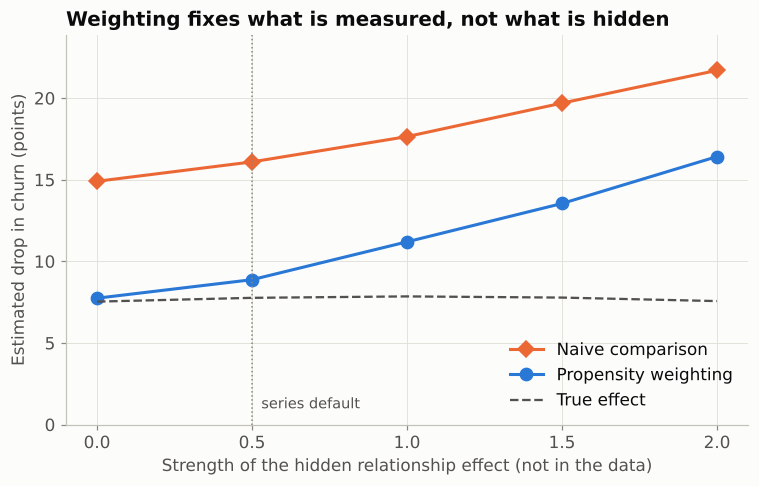

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.6))
x = sweep.index
ax.plot(x, sweep["Naive"], color=P.ORANGE, marker="D", markersize=7, label="Naive comparison")
ax.plot(x, sweep["Propensity weighting"], color=P.BLUE, marker="o", markersize=8, label="Propensity weighting")
ax.plot(x, sweep["Truth"], color=P.INK_SECONDARY, linestyle="--", linewidth=1.5, label="True effect")
ax.axvline(0.5, color=P.INK_MUTED, linewidth=1, linestyle=":")
ax.text(0.53, 1.0, "series default", color=P.INK_SECONDARY, fontsize=9.5)
ax.set_xticks(x)
ax.set_xlabel("Strength of the hidden relationship effect (not in the data)")
ax.set_ylabel("Estimated drop in churn (points)")
ax.set_ylim(0, sweep.values.max() * 1.1)
ax.legend(loc="lower right")
ax.set_title("Weighting fixes what is measured, not what is hidden")
P.save(fig, "10_hidden_confounding")
plt.show()

With no hidden factor, weighting lands on the truth. As the hidden relationship grows stronger, weighting still removes the part of the bias explained by tenure, meetings, revenue and complaints, but the rest survives. At the strongest setting the weighted estimate is still about double the truth, and nothing in the data warns you.

Two practical responses:

- **Better proxies.** Meeting frequency, years with the same RM, number of senior contacts, how often the client accepts invitations: each captures part of the relationship and moves it from hidden to measured.
- **Sensitivity analysis.** Ask how strong a hidden factor would have to be to explain away the effect. If a plausible one could, treat the estimate with caution. (Tools such as E-values and the sensitivity modules in DoWhy and EconML do this formally.)

Neither removes the problem. Only one thing does.

## 2. The random holdout

If a random draw, not a person, decides who is contacted, the contacted and not-contacted clients are alike in **every** respect, recorded or not, including relationship strength. That is the whole point of randomisation, and it can be added to the normal process at small cost:

1. build the RM list as usual (Part 7: highest net value within capacity);
2. randomly hold back a share of the list, say 20%, and do not contact them this cycle;
3. after six months, compare churn among contacted and held-back clients.

The pipeline below does steps 1 and 2 from RM-chosen history, using everything from Parts 3 to 9: propensity weights, a weighted T-learner, net value, capacity and a random holdout.

In [4]:
history = generate_bank(assignment="rm_biased", seed=SERIES_SEED)   # past cycles, RM-chosen
live = generate_bank(assignment="rm_biased", seed=2026)             # this cycle's flagged clients

rm_list, parts = run_cycle(history, live, capacity=500, holdout_share=0.2, seed=0)
rm_list["action"].value_counts().rename("clients").to_frame()

,clients
action,
negotiate,404
hold back,96


Now play the six months forward. The synthetic bank knows each client's true churn probability with and without pricing, so outcomes can be simulated. One run is what the business would actually see:

In [5]:
one_cycle = holdout_readout(simulate_outcomes(rm_list, seed=7))
pd.Series({
    "churn among negotiated clients": f"{one_cycle['churn_negotiated']:.1%}",
    "churn among held-back clients": f"{one_cycle['churn_held_back']:.1%}",
    "measured uplift (held back - negotiated)": f"{100 * one_cycle['measured_uplift']:.1f} pts",
    "model's predicted uplift for these clients": f"{100 * one_cycle['predicted_uplift']:.1f} pts",
    "true uplift for these clients": f"{100 * one_cycle['true_uplift']:.1f} pts",
}).to_frame("one cycle")

,one cycle
churn among negotiated clients,17.6%
churn among held-back clients,29.2%
measured uplift (held back - negotiated),11.6 pts
model's predicted uplift for these clients,18.3 pts
true uplift for these clients,9.8 pts


One cycle is a single draw. Replay the same six months 1,000 times with fresh randomness to see how much a holdout of this size can move:

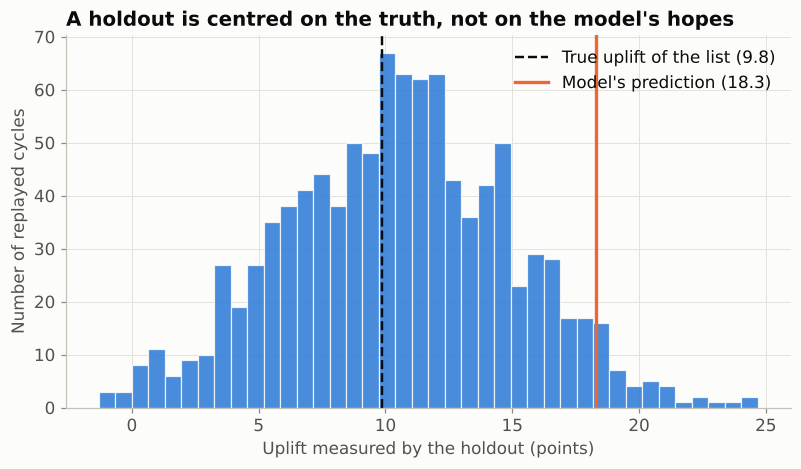

Average measured uplift over 1,000 replays: 10.5 pts (truth 9.8)
90% of single cycles read between 3.3 and 18.0 pts
Pooling four cycles narrows that to 6.5 to 14.5 pts


In [6]:
replays = np.array([holdout_readout(simulate_outcomes(rm_list, seed=s))["measured_uplift"] for s in range(1000)])
true_u, pred_u = 100 * one_cycle["true_uplift"], 100 * one_cycle["predicted_uplift"]

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.hist(100 * replays, bins=40, color=P.BLUE, alpha=0.85, edgecolor=P.SURFACE, linewidth=0.8)
ax.axvline(true_u, color=P.INK, linestyle="--", linewidth=1.6, label=f"True uplift of the list ({true_u:.1f})")
ax.axvline(pred_u, color=P.ORANGE, linewidth=2.2, label=f"Model's prediction ({pred_u:.1f})")
ax.set_xlabel("Uplift measured by the holdout (points)")
ax.set_ylabel("Number of replayed cycles")
ax.legend(loc="upper right")
ax.set_title("A holdout is centred on the truth, not on the model's hopes")
P.save(fig, "10_holdout_replays")
plt.show()

lo, hi = np.quantile(100 * replays, [0.05, 0.95])
print(f"Average measured uplift over 1,000 replays: {100 * replays.mean():.1f} pts (truth {true_u:.1f})")
print(f"90% of single cycles read between {lo:.1f} and {hi:.1f} pts")
four_cycles = 100 * replays[:1000].reshape(250, 4).mean(axis=1)
lo4, hi4 = np.quantile(four_cycles, [0.05, 0.95])
print(f"Pooling four cycles narrows that to {lo4:.1f} to {hi4:.1f} pts")

Three things to take from this chart:

- **The holdout is unbiased.** Over many cycles it centres close to the true uplift of the list (the small gap is chance in which clients were held back), hidden relationship and all. No model assumption is involved: it is a plain comparison of two randomly formed groups.
- **The model was optimistic.** Its prediction sits well to the right of the truth, the same optimism seen in Parts 5 and 7. The holdout is how a bank finds that out, and how it sizes the business case honestly.
- **One cycle is noisy.** With about 100 held-back clients, a single cycle can read anywhere across a wide range. Pool cycles, report ranges, and do not over-react to one quarter.

The held-back clients do one more job: next cycle, they and the contacted clients form a **randomised** training set. Over a few cycles the bank replaces RM-chosen history with clean data, and the propensity correction matters less and less.

## 3. Selling a holdout to RMs

The objection is always the same: *you want me to not call an at-risk client?* Practical answers:

- **Keep it small.** 15 to 20% of the list is enough when pooled across cycles.
- **Delay, don't deny.** Held-back clients go to the top of next cycle's list if they still qualify.
- **Hold back from the list, not from the relationship.** RMs keep normal service contact; only the pricing negotiation is withheld.
- **Rotate fairly.** The draw is random and visible, not a judgement about any RM's clients.
- **Frame it as measurement.** Without a holdout nobody can prove the programme works; with one, the RMs' effort shows up as a number the business believes.

## 4. The whole pipeline

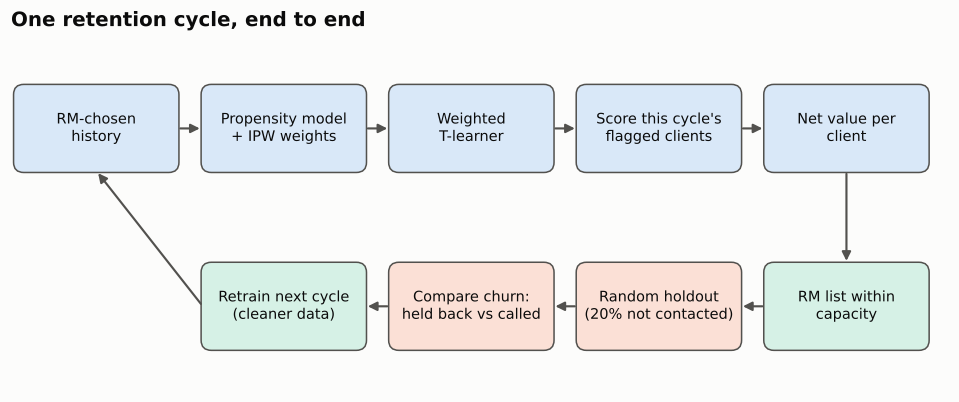

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 11)
ax.set_ylim(0, 4.2)
ax.axis("off")

steps_top = [("RM-chosen\nhistory", 1.0), ("Propensity model\n+ IPW weights", 3.2), ("Weighted\nT-learner", 5.4),
             ("Score this cycle's\nflagged clients", 7.6), ("Net value per\nclient", 9.8)]
steps_bottom = [("Retrain next cycle\n(cleaner data)", 3.2), ("Compare churn:\nheld back vs called", 5.4),
                ("Random holdout\n(20% not contacted)", 7.6), ("RM list within\ncapacity", 9.8)]

def box(x, y, text, color):
    ax.add_patch(FancyBboxPatch((x - 0.95, y - 0.5), 1.9, 1.0, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=color, edgecolor=P.INK_SECONDARY, linewidth=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=9.5, color=P.INK)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=P.INK_SECONDARY, linewidth=1.4, mutation_scale=12))

for i, (t, x) in enumerate(steps_top):
    box(x, 3.1, t, "#d9e8f8")
    if i:
        arrow(steps_top[i - 1][1] + 0.95, 3.1, x - 0.95, 3.1)
for i, (t, x) in enumerate(steps_bottom):
    box(x, 1.0, t, "#fbe0d6" if "holdout" in t or "Compare" in t else "#d6f1e6")
arrow(9.8, 2.6, 9.8, 1.5)
for i in range(len(steps_bottom) - 1, 0, -1):
    arrow(steps_bottom[i][1] - 0.95, 1.0, steps_bottom[i - 1][1] + 0.95, 1.0)
arrow(2.25, 1.0, 1.0, 2.6)
ax.set_title("One retention cycle, end to end", loc="left")
P.save(fig, "10_pipeline")
plt.show()

In code, the top row and the holdout are one call to `run_cycle`; the rest of the loop is the next cycle's history. Every step maps to a part of the series:

| Step | Part |
|---|---|
| Treated vs control, start dates, leakage | 3 |
| T-learner | 4 |
| Validation: bins, Qini, uplift@k | 5, 6 |
| Net value and capacity | 7 |
| Why history is biased | 8 |
| Propensity weights | 9 |
| Random holdout | 10 |

Here is what this cycle's list is worth, by the model's estimate and in truth:

In [8]:
negotiated = rm_list[rm_list["action"] == "negotiate"]
pd.Series({
    "clients negotiated": len(negotiated),
    "model's expected net value ($M)": negotiated["pred_net_value"].sum() / 1e6,
    "true net value ($M)": true_net_value(negotiated).sum() / 1e6,
}).round(1).to_frame("this cycle")

,this cycle
clients negotiated,404.000
model's expected net value ($M),271.400
true net value ($M),78.900


The list makes real money, but less than the model claims. Report the holdout's measured number, not the model's.

## 5. Where to go next

The T-learner was chosen for clarity. With more data, or a need for sharper estimates, look at:

- **X-learner:** uses each group's model to impute the other group's missing outcome; strong when treated clients are few, as here.
- **Doubly robust (DR) learners:** combine an outcome model with propensity weights, and stay consistent if either one is right.
- **Causal forests:** trees built to split on differences in treatment effect rather than on churn.
- **Uplift trees** and the **transformed-outcome** approach: model uplift directly in one step.

Python libraries: `causalml`, `EconML`, `scikit-uplift` and `DoWhy`.

## Lessons from the series

1. **Ask the right question.** A churn model finds who will leave; uplift finds who will stay *because* you acted.
2. **Respect the four kinds of client.** The riskiest clients are often lost causes, and some clients are sleeping dogs.
3. **Get the data right first:** comparable controls, no other interventions in the control group, start dates, no leakage.
4. **Grade uplift on groups:** bins, Qini and uplift@k, not AUC, and expect the top of the ranking to be optimistic.
5. **Decide in dollars:** net value after the concession and the RM's time, within capacity.
6. **History is biased.** RMs choose easy clients; propensity weighting corrects what is measured.
7. **Hidden bias needs randomisation.** A small, routine holdout turns every cycle into an honest measurement and cleaner training data.

## Takeaways

- Propensity weighting removes **measured** confounding only; a hidden relationship can leave the estimate doubled with no warning in the data.
- A **random holdout** is unbiased whatever the hidden factors, reveals model optimism, and builds randomised training data over time.
- One cycle's holdout is noisy: **pool cycles** and report ranges.
- The full loop runs from biased history to an RM list, a holdout, a measurement and a better model next cycle.